# SeismicDataset. Подготовка сейсмического датасета #

## 1.5. От эталонного расчёта к массовому ##

Как сократить стоимость сейсмограммы, сохранив физическую постановку и возможность проверить ответ?

In [1]:
import matplotlib.pyplot as plt
from IPython.display import Image, display

from scripts.project_paths import PROJECT_ROOT as ROOT
from scripts.reporting import mapping, number, read_json, sequence

### Первые пять независимых источников ###

Первый опыт пакетирования ещё относился к квадратному ядру 700 × 700 м с массовым слоем 175 м и внешним ABC. Для пяти положений источника в одном запуске разместили пять независимых копий задачи с общим шагом. Получилось 146,88 с интегрирования и 150,22 с со сборкой и подготовкой. В прежней очереди сумма времён пяти отдельных опытов той же модели составляла 161,66 с. Этот замер делался раньше и по другой границе таймера. Опыт показал осуществимость пакетирования и одновременно его цену: дублировались геометрия, материал и подготовка. [Замер пакета](data/dev_1_4_server_preparation/batch_probe_saturn_v1/full_results.json) · [Исходные времена пяти запусков](data/dev_1_4_server_preparation/batch_probe_saturn_v1/production_reference_timings.json).

### Специализация решателя ###

На двухслойной модели 1400×700 м при p5 и шаге около 5 м сравнили универсальный тензорный решатель и специализированный сейсмический CUDA-вариант. Время интегрирования на A100 уменьшилось примерно с 45,3 до 35,3 с при обеих частотах 15 и 30 Гц. Полная запись полей была нужна при отладке. Для датасета достаточно записывать скорости в 140 приёмниках. Это отделило стоимость интегрирования от вывода миллионов узлов.

In [2]:
specialized = read_json(ROOT / "data/dev_1_5_geometry_frequency/solver_comparison_v1/analysis.json")
for sample in sequence(specialized["timings"]):
    run = mapping(sample)
    print(f"{run['frequency_hz']} Гц, {run['backend']}: {number(run['median_run_seconds']):.2f} с")

15 Гц, tenzor: 45.32 с
15 Гц, seismic: 35.33 с
30 Гц, tenzor: 45.35 с
30 Гц, seismic: 35.32 с


### Одинаковые входы и разное число источников ###

На EFVB00001 сопоставили четыре последовательных опыта p6, совместный пакет четырёх p64s и пакет семи p67s. Приёмник, шаг и устройство одинаковы. Приведены медианы трёх повторов после прогрева на A100. Время run включает ожидание конца интегрирования, total — также подготовку, проверки и запись.

p6: run 14.666 с, total 18.539 с
p64s: run 9.776 с, total 12.336 с
p67s: run 16.782 с, total 19.801 с
Проверок: 220; максимальная относительная L2 по поверхности: 3.26e-14
surface           112 сравнений, максимальная относительная L2 3.26e-14
state.npy          48 сравнений, максимальная относительная L2 9.83e-13
pml_history.npy    32 сравнений, максимальная относительная L2 3.37e-14
mirror             28 сравнений, максимальная относительная L2 2.82e-13


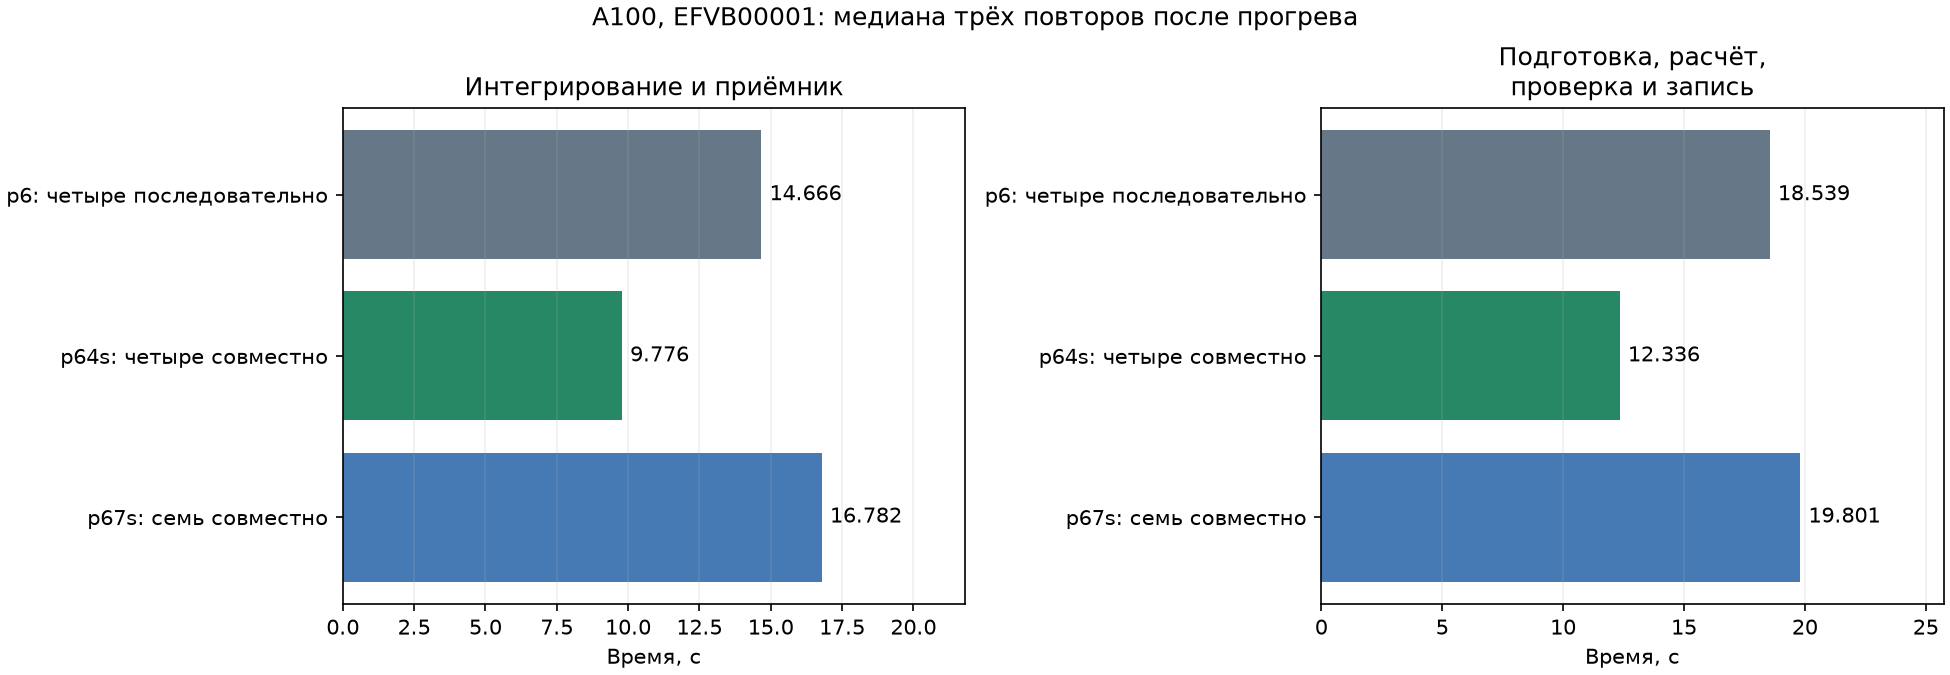

In [3]:
benchmark = read_json((ROOT / "data/dev_1_6_p64s_production/comparison_v1/analysis/metrics.json"))
for variant, timing in mapping(benchmark["timings_median3"]).items():
    item = mapping(timing)
    print(f"{variant}: run {number(item['run_seconds']):.3f} с, total {number(item['total_seconds']):.3f} с")
checks = [mapping(item) for item in sequence(benchmark["checks"])]
assert all(check["pass"] for check in checks)
surface = [number(c["relative_l2"]) for c in checks if c["kind"] == "surface"]
print(f"Проверок: {len(checks)}; максимальная относительная L2 по поверхности: {max(surface):.3g}")
for kind in ("surface", "state.npy", "pml_history.npy", "mirror"):
    values = [number(c["relative_l2"]) for c in checks if c["kind"] == kind]
    print(f"{kind:16}  {len(values):3} сравнений, максимальная относительная L2 {max(values):.3g}")

display(Image(filename=str(ROOT / "img/dev_1_6_p64s_production/comparison_v2/timings.png"), width=850))

### Где удалось сократить стоимость ###

В таблице времена интегрирования на A100 для 1 с физического времени. Сравнивать ускорение следует внутри строки. От строки к строке менялись способ поглощения, число элементов, количество источников и состав выдачи.

| Опыт и объём выдачи | Что изменили | Время run, с |
|---|---|---:|
| Два слоя, 1400 × 700 м, h5/p5, массовый слой и ABC, 1 источник | Универсальный tenzor → специализированный seismic, затем отдельная серия с фиксированным p5 | 45,32 → 35,33 при 15 Гц; 45,35 → 35,32 при 30 Гц. В следующей серии 45,33 → 33,42 → 31,46 |
| Та же модель, демпфирование только на узлах слоя | Универсальный → сейсмический → фиксированный порядок | p4: 20,56 → 13,46 → 12,41; p5: 45,42 → 29,40 → 27,52 |
| Два слоя, p4/h5, 1 источник | PML100 с ABC → PML350 без ABC, каждый на своём шаге | 13,12 → 7,80 |
| PML350 без ABC, 1 источник, фиксированные ядра p | h5/p4, h5/p5, h10/p6, h10/p7, каждый на своём шаге | 7,04; 14,62; 4,09; 6,92 |
| PML350, p6/h10, 7 источников, 21 кадр полей и запись всего верха | Семь отдельных расчётов → пакет семи сеток | 28,77 → 26,60 |
| Та же модель, выдача только сейсмограмм всего верха | Семь отдельных → пакет семи сеток | 26,23 → 23,76 |
| Семь сейсмограмм, одна геометрия | Пакет сеток p6 → p6_7s с общей сеткой, семью состояниями и встроенной силой | 23,69 → 23,35; со сборкой и подготовкой 29,93 → 24,69 |
| Семь источников, запись всего верха | p6_7s → p67s, синхронный приёмник → асинхронный | 23,33 → 16,96 → 16,79 |
| Четыре прямых источника EFVB, выдача 140 приёмников | Четыре одиночных p6 → p64s; рядом контрольный p67s с семью | 14,67 → 9,78; семь за 16,78 |

Профилирование раннего seismic показало, что на A100 около 44% времени ядер приходилось на вычисление отклика материала. Фиксация порядка и ограничение носителя демпфирования уменьшили цену каждого шага. С введением PML появились дополнительные переменные и вычисления, поэтому время всего расчёта зависело также от числа устойчивых шагов. На одной и той же сетке p4 включение ABC давало 34 подшага на 1 мс вместо 9, на p5 — 51 вместо 13. Внешний импедансный оператор существенно ограничивал шаг по спектральной оценке. При сравнении на общем K34 широкий PML350 без ABC занимал 27,00 с; выигрыш по времени интегрирования появился лишь при переходе на его собственный допустимый шаг. Контроль удвоением K отделил изменение временной погрешности от ошибки отражения.

В семиисточниковой ветви основной выигрыш от общей геометрии первоначально пришёлся на подготовку. После оптимизации p67s собственно PML занимал около 50% времени ядер, корректоры — 30%, обычный материал — 18%. Синхронная запись добавляла около 0,20 с к 16,76 с без приёмника; для асинхронной разность 0,03 с сопоставима с разбросом. Это объясняет, почему дальнейший выигрыш получили специализацией числа источников и использованием симметрии EFVB. Четыре физически вычисленных возбуждения и семь представимых положений подробно разобраны в главе 1.6.

Ниже оставлены только семиисточниковые опыты с одной и той же двухслойной моделью, p6/10 м и K9. В них источник занимал семь позиций от 175 до 1225 м через 175 м, а на поверхности записывался весь верх (1261 узел). Последняя производственная строка таблицы относится уже к другой расстановке и 140 приёмникам. Разделение на рисунке показывает, где ускорился пакет и где часть времени сэкономила смена режима выдачи.

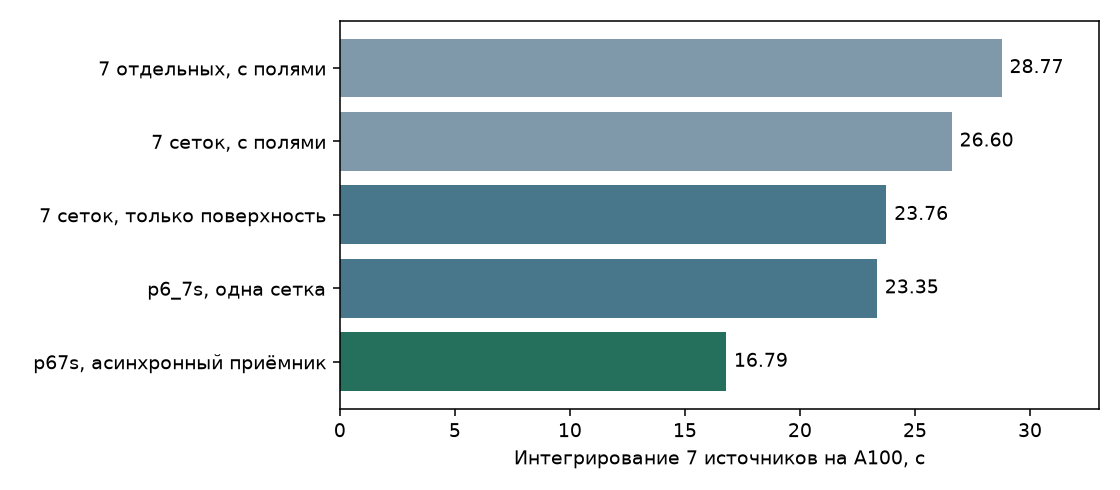

In [4]:
history_root = ROOT / "data/dev_1_5_geometry_frequency"
with_frames = read_json(history_root / "pml_p6_sources7_v1/analysis/metrics.json")
only_surface = read_json(history_root / "pml_p6_sources7_surface_v1/analysis/metrics.json")
common_mesh = read_json(history_root / "p6_7s_comparison_v2/analysis/metrics.json")
receivers = read_json(history_root / "p67s_receiver_v1/analysis/metrics.json")
shared_time = next(mapping(v) for v in sequence(common_mesh["timings"]) if mapping(v)["variant"] == "p6_7s")
async_time = next(mapping(v) for v in sequence(receivers["timings"]) if mapping(v)["mode"] == "new_async")
elapsed = [number(with_frames["median_sequential_run_seconds"]), number(with_frames["median_batch_run_seconds"]),
           number(only_surface["median_batch_run_seconds"]), number(shared_time["median_run_seconds"]),
           number(async_time["median_run_seconds"])]
labels = ["7 отдельных, с полями", "7 сеток, с полями", "7 сеток, только поверхность", "p6_7s, одна сетка", "p67s, асинхронный приёмник"]
fig, axis = plt.subplots(figsize=(8, 3.5))
bars = axis.barh(labels, elapsed, color=["#8099aa", "#8099aa", "#48768a", "#48768a", "#24705d"])
axis.invert_yaxis()
axis.set(xlabel="Интегрирование 7 источников на A100, с", xlim=(0, 33))
axis.bar_label(bars, fmt="%.2f", padding=4)
fig.tight_layout()
fig.savefig(ROOT / "img/dev_1_6_p64s_production/comparison_v2/seven_cost.png", dpi=140)
plt.close(fig)
display(Image(filename=str(ROOT / "img/dev_1_6_p64s_production/comparison_v2/seven_cost.png"), width=800))

### Когда достаточно четырёх опытов ###

Для четырёх требуемых источников пакет сократил время интегрирования примерно в 1,5 раза. В EFVB горизонтальная симметрия позволяет отразить положение источника и порядок приёмников относительно x=700 м. При отражении Vx меняет знак, Vy сохраняет. Четыре прямых опыта охватывают семь положений с учётом центрального. В произвольной ECVB такого основания нет: для семи положений нужны семь реальных возбуждений. В наборе EFVB хранятся четыре прямо рассчитанных записи.

### Вывод ###

Время четырёх опытов на A100 уменьшилось с 14,67 до 9,78 с. Симметрия EFVB обосновывает четыре прямых источника. Для семи положений в произвольной ECVB предусмотрен пакет p67s.